# How omitted confounding distorts performance

This native Julia companion preserves the original structural equations, causal targets, parameters, sample sizes, seeds, repetitions and decision rules. Preserved primitive NumPy draws retain the original samples; Julia generates the observations and computes all estimates. Native exception checks cover the corresponding rejection conditions. Figures use the requested dark theme and outputs are saved under `outputs/julia`.

Suppose an exposure and outcome are generated by a common cause according to:

$$
X=\delta Z+V,
\qquad
Y=\beta X+\gamma Z+U,
\qquad
\widetilde\beta
=\beta+\frac{\gamma\delta}{1+\delta^2}.
$$

Here, $Z$ is the omitted common cause, $X$ is the exposure, $Y$ is the outcome, $V$ and $U$ are independent centered disturbances with unit variance, $\delta$ links $Z$ to $X$, $\beta$ is the direct effect of $X$ on $Y$, $\gamma$ links $Z$ to $Y$, and $\widetilde\beta$ is the population coefficient from regressing $Y$ on $X$ while omitting $Z$.

Row,Direct effect,Common-cause outcome link,Common-cause exposure link,Omitted coefficient,Omission bias,Formula difference
,Float64,Float64,Float64,Float64,Float64,Float64
1,1.0,3.0,1.0,2.5,1.5,0.0
2,-0.7,1.2,-0.4,-1.11379,-0.413793,0.0
3,0.0,-2.0,3.0,-0.6,-0.6,0.0
4,2.5,0.0,-8.0,2.5,0.0,0.0


Row,Specification,Exposure coefficient,Population target,Explained variance,Observations,Seed
,String,Float64,Float64,Float64,Int64,Int64
1,Common cause omitted,2.49188,2.5,0.693785,5000,0
2,Common cause included,1.00072,1.0,0.943705,5000,0


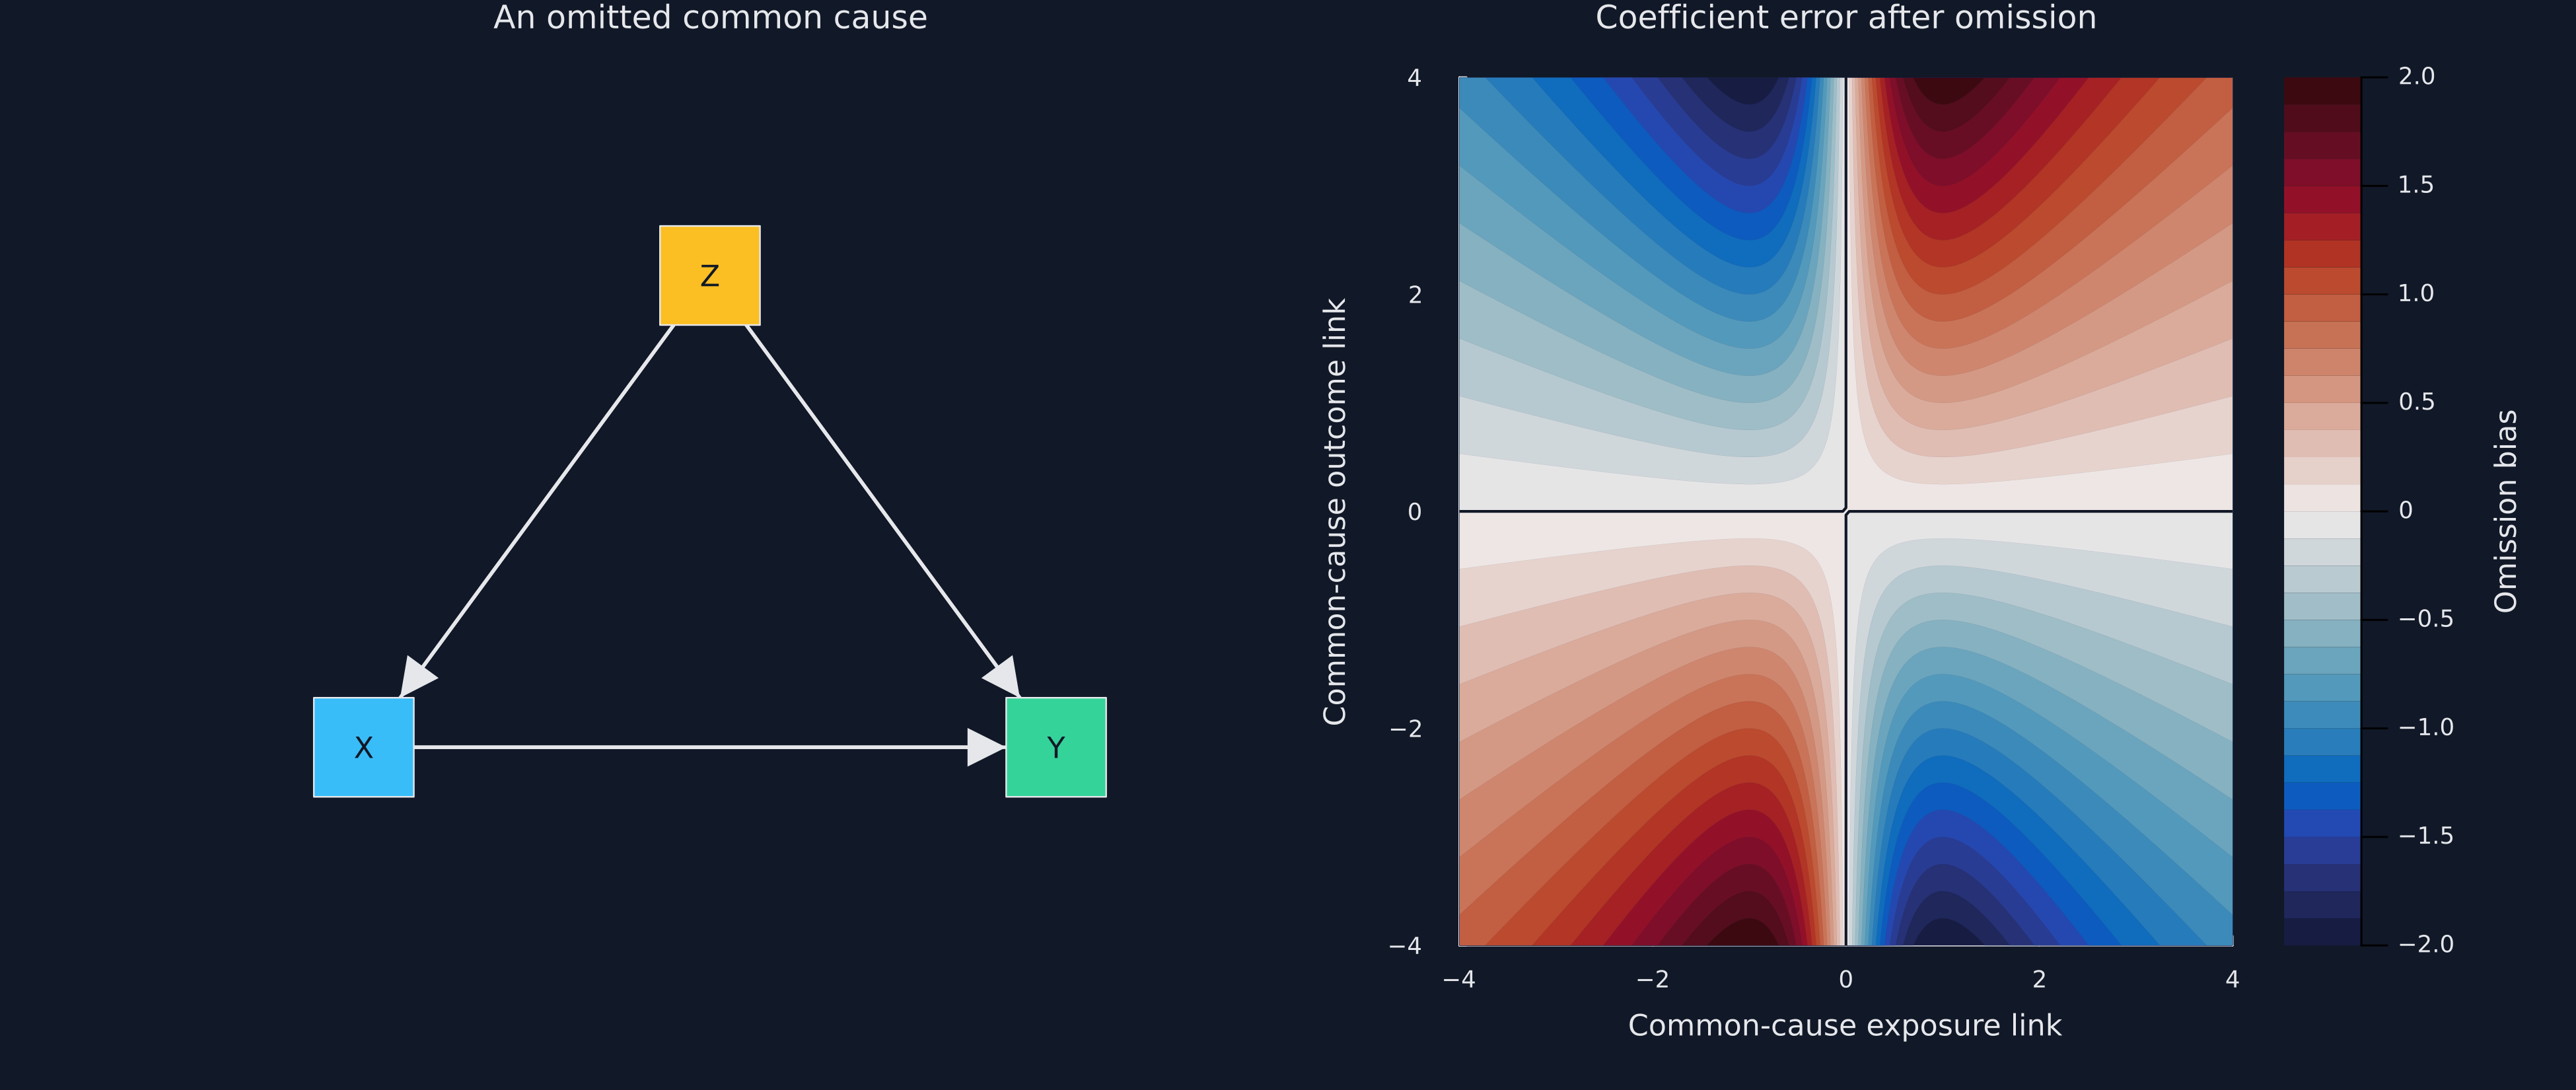

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("04_factor_mirage");
using CSV, TOML
using RiskLabAI.CausalFactorAnalysis
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
include(joinpath("..","support","BookIdentificationStudy.jl"))
using .BookIdentificationStudy
include(joinpath("..","support","BookTreatmentStudy.jl"))
using .BookTreatmentStudy: histogram_peak
include(joinpath("..","support","BookMirageStudy.jl"))
using .BookMirageStudy
chapter_palette=(background="#111827",axes="#111827",text="#E5E7EB",cyan="#38BDF8",amber="#FBBF24",green="#34D399",rose="#FB7185",grid="#374151")
default(background_color=chapter_palette.background,background_color_inside=chapter_palette.axes,foreground_color=chapter_palette.text,gridcolor=chapter_palette.grid,fontfamily="sans-serif",left_margin=10Plots.mm,bottom_margin=10Plots.mm,titlefontsize=11,guidefontsize=10)
store=PrimitiveStore(joinpath("..","data","chapter04_random_inputs"),"mirage")
captions=Dict("confounder_standardized_coefficients"=>"Standardized omitted-confounder coefficients.","confounder_generated_check"=>"A visible fixed-seed confounder experiment.","confounder_general_variance"=>"Omitted coefficients with general positive variances.","confounder_return_examples"=>"Correct and omitted-confounder expected returns.","confounder_static_gap"=>"The exact fixed-link forecast-return gap.","confounder_zero_boundaries"=>"Exact coefficient and shifted-return sign boundaries.","confounder_input_checks"=>"Input-boundary checks for omitted-confounder calculations.","confounder_numerical_stability"=>"Finite-scaling and sign-preservation checks.","confounder_section_summary"=>"Main conclusions from the omitted-confounder experiments.","collider_standardized_coefficients"=>"Population coefficients after conditioning on the collider.","collider_generated_check"=>"A visible fixed-seed collider experiment.","collider_general_variance"=>"Collider-conditioned coefficients with general variances.","collider_return_examples"=>"Negative expected returns after collider conditioning.","collider_return_boundaries"=>"Exact equality and zero boundaries for collider returns.","collider_diagnostic_example"=>"Model-comparison quantities for the released Appendix example.","collider_adjusted_threshold"=>"The strict adjusted explained-variance threshold.","collider_expected_signals"=>"Expected coefficient signals under the population approximation.","collider_conditional_selection"=>"Marginal independence and collider-induced conditional association.","collider_input_checks"=>"Input-boundary checks for collider calculations.","collider_numerical_stability"=>"Finite-scaling and sign-preservation checks for collider calculations.","collider_section_summary"=>"Main conclusions from the collider experiments.","specification_population_targets"=>"Exact population targets for the three structural systems.","specification_seed_zero_samples"=>"Seed-zero sample diagnostics with 5,000 observations.","specification_visible_generation_parity"=>"Visible generation agrees with the released fixed-seed experiments.","specification_population_sample_gaps"=>"Population targets and seed-zero sample errors.","specification_repeated_convergence"=>"Repeated-sample convergence to the population coefficient targets.","specification_seed_variation"=>"Coefficient variation across fixed-seed generated samples.","specification_input_checks"=>"Invalid sample-size and seed checks for all three experiments.","specification_record_checks"=>"Repeatability and immutable-record checks.","specification_public_surface"=>"Released public records and functions covered by Chapter 26.","specification_section_summary"=>"How the three wrong specifications change the exposure coefficient.")
function table(values,name)
    shown=copy(values)
    for column in names(shown)
        if all(value->value isa Bool,shown[!,column])
            shown[!,column]=ifelse.(shown[!,column],"Yes","No")
        end
    end
    save_table(shown,paths,name;caption=captions[name],label="tab:chapter26-"*replace(name,"_"=>"-"))
    return nothing
end
function assert_artifacts(figures,tables)
    @assert all(name->isfile(joinpath(paths.figures,name*".pdf")),figures)
    @assert all(name->isfile(joinpath(paths.tables,name*".tex")),tables)
end
function graph_panel(nodes,edges,positions,title)
    graph=DirectedGraph(nodes,edges)
    xs,ys=[positions[node][1] for node in graph.nodes],[positions[node][2] for node in graph.nodes]
    spanx,spany=max(maximum(xs)-minimum(xs),2.),max(maximum(ys)-minimum(ys),1.5)
    rx,ry=.065spanx,.07spany
    figure=plot(;title,legend=false,axis=false,grid=false,xlims=(minimum(xs)-.22spanx,maximum(xs)+.22spanx),ylims=(minimum(ys)-.28spany,maximum(ys)+.28spany),widen=false)
    for (left,right) in graph.edges
        x1,y1=positions[left]
        x2,y2=positions[right]
        dx,dy=x2-x1,y2-y1
        fraction=min(abs(dx)>0 ? rx/abs(dx) : Inf,abs(dy)>0 ? ry/abs(dy) : Inf,.42)
        plot!(figure,[x1+fraction*dx,x2-fraction*dx],[y1+fraction*dy,y2-fraction*dy];color=chapter_palette.text,linewidth=1.8,arrow=Plots.arrow(:closed,.14,.12),label="")
    end
    for node in graph.nodes
        x,y=positions[node]
        color=node=="X" ? chapter_palette.cyan : node=="Y" ? chapter_palette.green : node=="W" || (node=="Z" && ("Z","X") in graph.edges) ? chapter_palette.amber : chapter_palette.rose
        plot!(figure,Shape([x-rx,x+rx,x+rx,x-rx],[y-ry,y-ry,y+ry,y+ry]);fillcolor=color,linecolor=chapter_palette.text,linewidth=.8,label="")
        annotate!(figure,x,y,text(node,10,chapter_palette.background,:center))
    end
    return figure
end
standardized_cases=[(1.,3.,1.),(-.7,1.2,-.4),(0.,-2.,3.),(2.5,0.,-8.)]
standardized_rows=Tuple[]
for (beta,gamma,delta) in standardized_cases
    value=confounder_undercontrolled_coefficient(beta,gamma,delta)
    push!(standardized_rows,(beta,gamma,delta,value,value-beta,value-(beta+gamma*delta/(1+delta^2))))
end
standardized_table=frame(["Direct effect","Common-cause outcome link","Common-cause exposure link","Omitted coefficient","Omission bias","Formula difference"],standardized_rows)
table(standardized_table,"confounder_standardized_coefficients")
beta,gamma,delta=1.,3.,1.
sample_size=5000
draws=primitive_sample(store,sample_size,0)
common_cause,exposure_noise,outcome_noise=draws[:,1],draws[:,2],draws[:,3]
exposure=delta.*common_cause+exposure_noise
outcome=beta.*exposure+gamma.*common_cause+outcome_noise
unconditioned=manual_diagnostics(outcome,[exposure],["Exposure"])
conditioned=manual_diagnostics(outcome,[exposure,common_cause],["Exposure","Common cause"])
generated_table=frame(["Specification","Exposure coefficient","Population target","Explained variance","Observations","Seed"],[("Common cause omitted",unconditioned.coefficients[2],confounder_undercontrolled_coefficient(beta,gamma,delta),unconditioned.r_squared,sample_size,0),("Common cause included",conditioned.coefficients[2],beta,conditioned.r_squared,sample_size,0)])
table(generated_table,"confounder_generated_check")
save_data(DataFrame("Common cause"=>common_cause,"Exposure noise"=>exposure_noise,"Outcome noise"=>outcome_noise,"Exposure"=>exposure,"Outcome"=>outcome),paths,"confounder_generated_values")
gamma_grid=collect(range(-4.,4.;length=241))
delta_grid=collect(range(-4.,4.;length=241))
bias_mesh=[g*d/(1+d^2) for g in gamma_grid,d in delta_grid]
graph=graph_panel(["Z","X","Y"],[("Z","X"),("Z","Y"),("X","Y")],Dict("Z"=>(.9,1.),"X"=>(0.,0.),"Y"=>(1.8,0.)),"An omitted common cause")
surface=contourf(delta_grid,gamma_grid,bias_mesh;levels=31,color=:balance,colorbar_title="Omission bias",xlabel="Common-cause exposure link",ylabel="Common-cause outcome link",title="Coefficient error after omission",linewidth=0)
contour!(surface,delta_grid,gamma_grid,bias_mesh;levels=[0.],color=chapter_palette.background,linewidth=1.4,colorbar_entry=false)
save_figure(plot(graph,surface;layout=(1,2),size=(1300,550)),paths,"confounder_graph_and_bias")
save_data(frame(["Outcome link","Exposure link","Omission bias"],[(g,d,bias_mesh[i,j]) for (i,g) in enumerate(gamma_grid) for (j,d) in enumerate(delta_grid)]),paths,"confounder_bias_surface");


## General disturbance variances

When the common cause and exposure disturbance have general positive variances, the omitted coefficient is:

$$
\widetilde\beta
=\beta
+\frac{\delta\gamma\sigma_Z^2}
{\delta^2\sigma_Z^2+\sigma_V^2}.
$$

Here, $\sigma_Z^2=\operatorname{Var}(Z)$ is the common-cause variance, $\sigma_V^2=\operatorname{Var}(V)$ is the exposure-disturbance variance, and $\beta$, $\gamma$, $\delta$, and $\widetilde\beta$ retain their earlier meanings; both variances must be strictly positive.

Row,Case,Direct effect,Outcome link,Exposure link,Common-cause variance,Exposure-noise variance,Omitted coefficient,Formula difference
,String,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,Released quickstart,2.0,3.0,4.0,5.0,6.0,2.69767,0.0
2,Unequal variances,0.75,-1.25,0.5,2.0,3.0,0.392857,0.0
3,Small common-cause variance,-0.4,2.5,-0.75,0.25,4.0,-0.513208,0.0
4,No outcome link,1.5,0.0,8.0,3.0,0.5,1.5,0.0
5,Unit variances,1.0,3.0,1.0,1.0,1.0,2.5,0.0


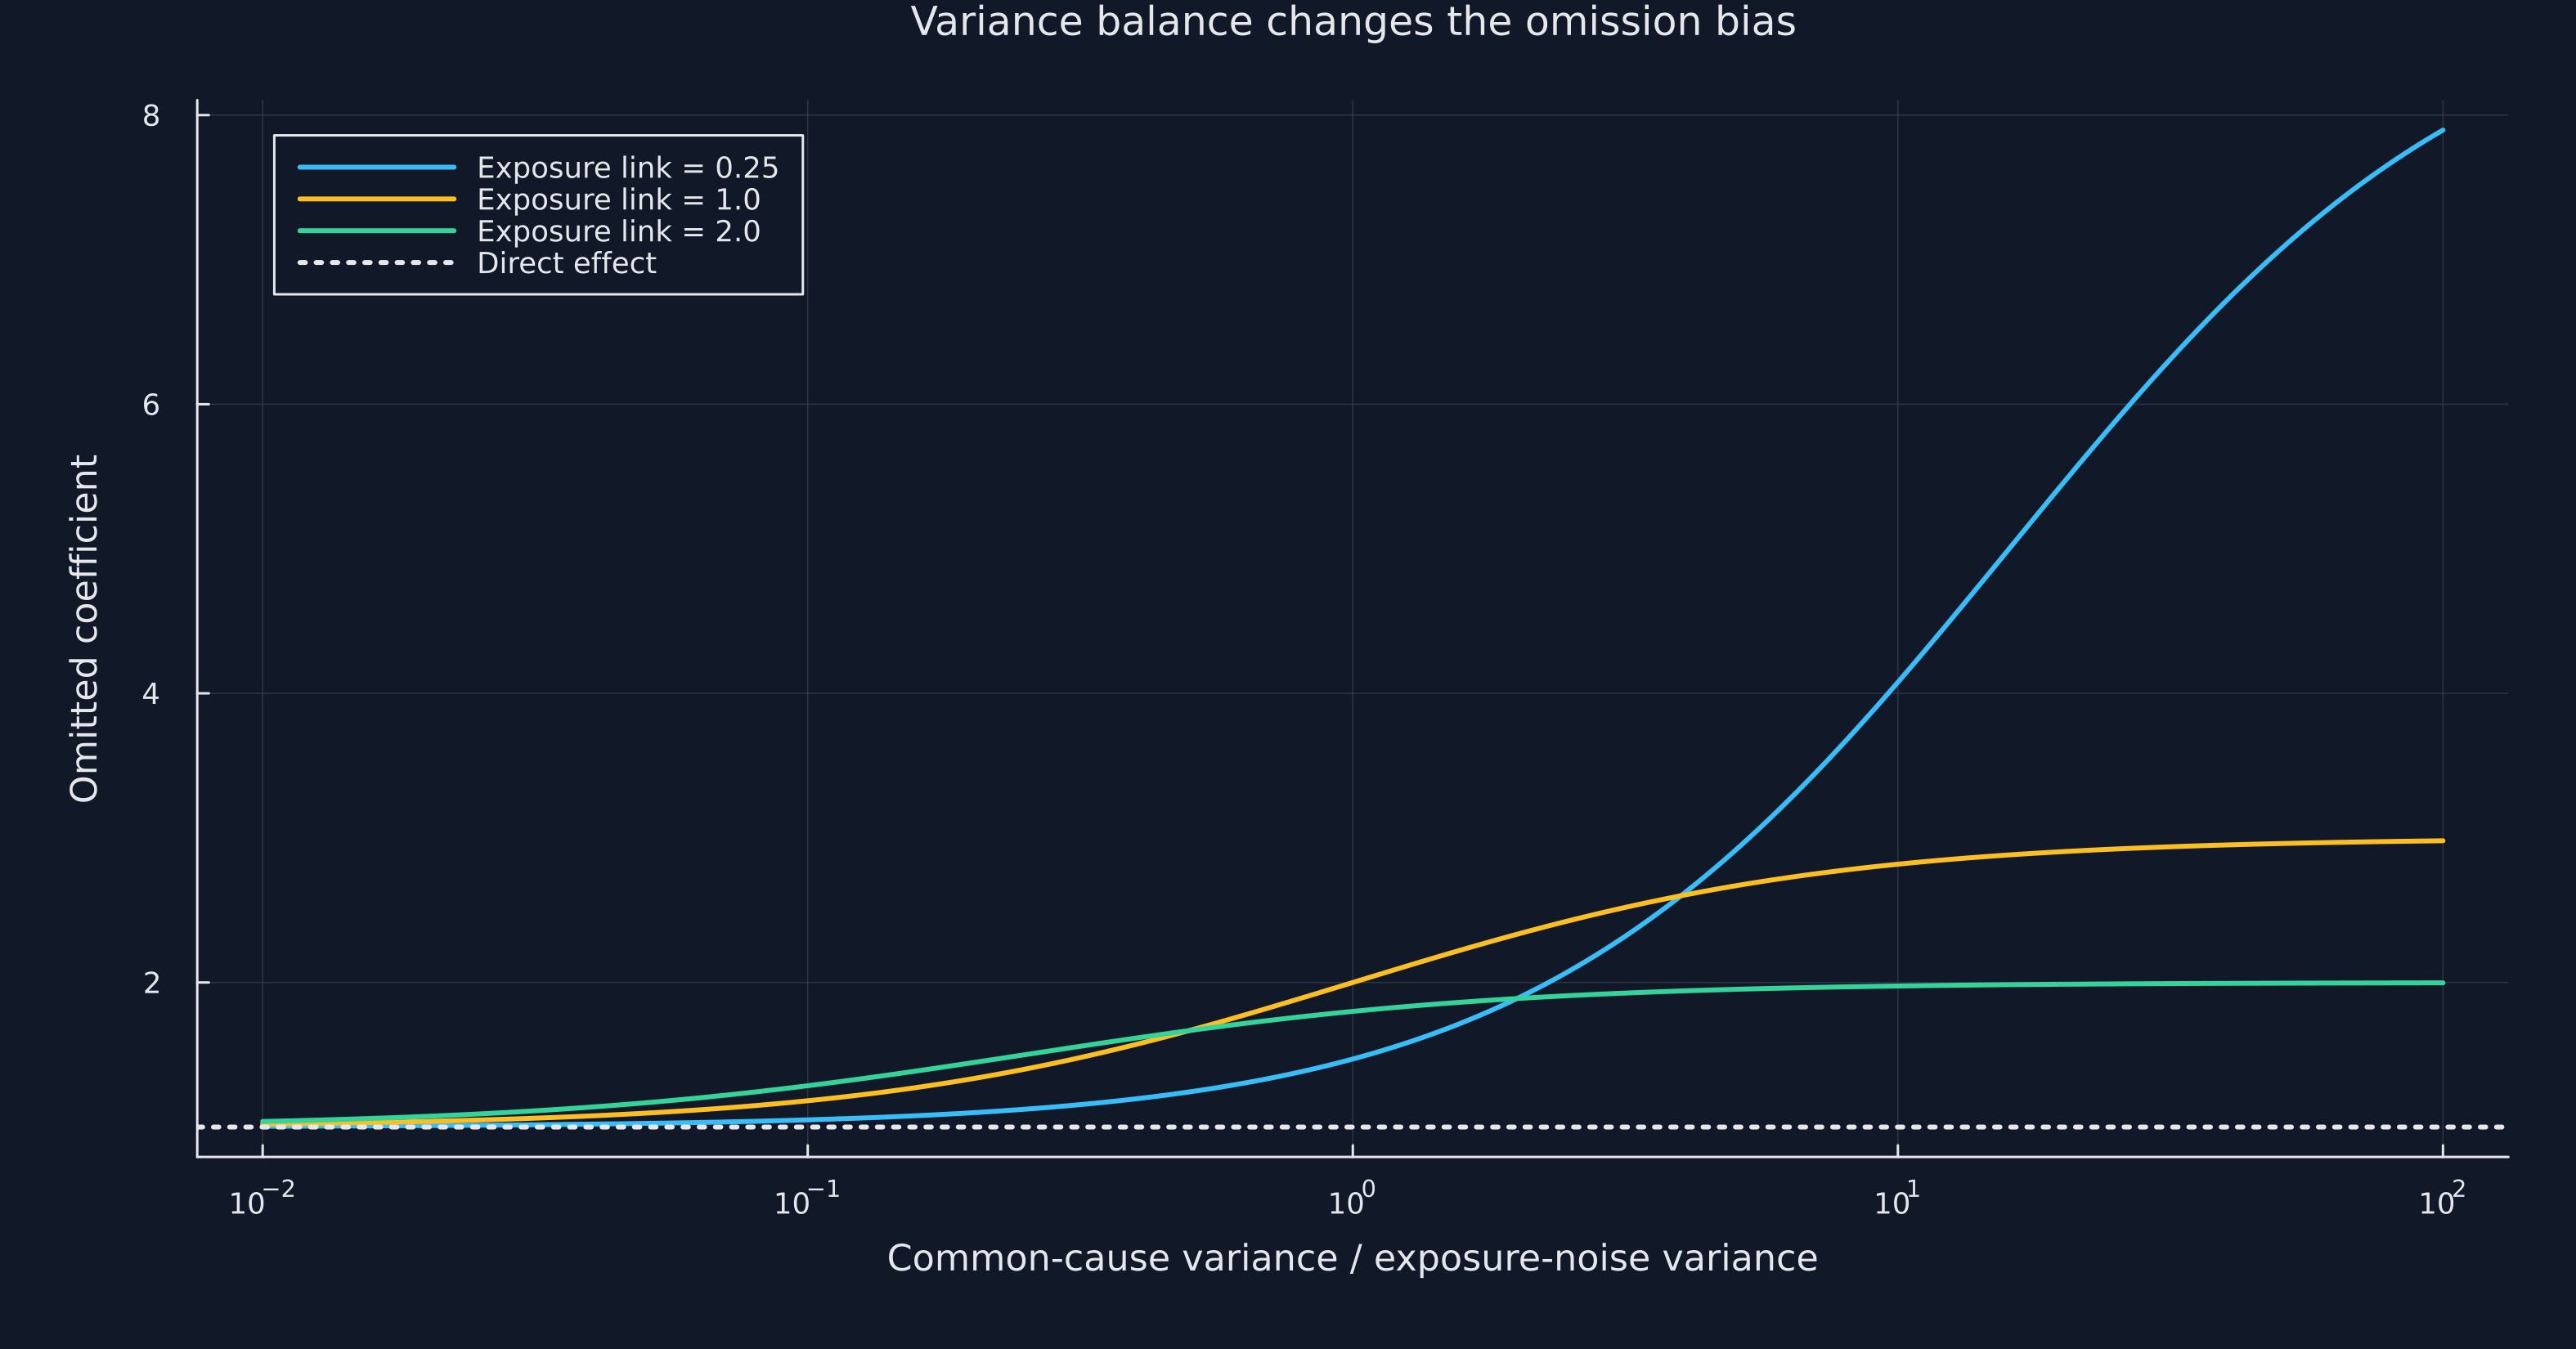

In [2]:
variance_cases=[("Released quickstart",2.,3.,4.,5.,6.),("Unequal variances",.75,-1.25,.5,2.,3.),("Small common-cause variance",-.4,2.5,-.75,.25,4.),("No outcome link",1.5,0.,8.,3.,.5),("Unit variances",1.,3.,1.,1.,1.)]
variance_rows=Tuple[]
for (name,beta,gamma,delta,common_variance,noise_variance) in variance_cases
    value=generalized_confounder_undercontrolled_coefficient(beta,gamma,delta;confounder_variance=common_variance,exposure_noise_variance=noise_variance)
    direct=beta+delta*gamma*common_variance/(delta^2*common_variance+noise_variance)
    push!(variance_rows,(name,beta,gamma,delta,common_variance,noise_variance,value,value-direct))
end
variance_table=frame(["Case","Direct effect","Outcome link","Exposure link","Common-cause variance","Exposure-noise variance","Omitted coefficient","Formula difference"],variance_rows)
table(variance_table,"confounder_general_variance")
ratio_grid=10.0 .^collect(range(-2.,2.;length=240))
variance_paths=Tuple[]
figure=plot(;xscale=:log10,xlabel="Common-cause variance / exposure-noise variance",ylabel="Omitted coefficient",title="Variance balance changes the omission bias",size=(1050,550),legend=:topleft)
for (link,color) in [(.25,chapter_palette.cyan),(1.,chapter_palette.amber),(2.,chapter_palette.green)]
    values=[generalized_confounder_undercontrolled_coefficient(1.,2.,link;confounder_variance=ratio,exposure_noise_variance=1.) for ratio in ratio_grid]
    plot!(figure,ratio_grid,values;color,linewidth=2,label="Exposure link = "*string(link))
    append!(variance_paths,[(link,ratio,value) for (ratio,value) in zip(ratio_grid,values)])
end
hline!(figure,[1.];color=chapter_palette.text,linestyle=:dot,label="Direct effect")
save_figure(figure,paths,"confounder_variance_ratio")
save_data(frame(["Exposure link","Variance ratio","Omitted coefficient"],variance_paths),paths,"confounder_variance_paths");


## Translating conditional factor returns into forecasts

The correct and omitted-confounder expected returns are given by:

$$
\begin{aligned}
R_C(x,z)&=(\beta x+\gamma z)^2,
&R_U(x;\delta_e,\delta_r)&=x^2\widetilde\beta(\delta_e)\widetilde\beta(\delta_r),\\
F_C(\delta_r)&=\beta^2+(\beta\delta_r+\gamma)^2,
&F_U(\delta_e,\delta_r)&=(1+\delta_r^2)\widetilde\beta(\delta_e)\widetilde\beta(\delta_r).
\end{aligned}
$$

Here, $R_C$ and $R_U$ are the correct and omitted-confounder factor returns at exposure values $x$ and $z$, $F_C$ and $F_U$ are their forecast returns after averaging over the exposure distribution, $\delta_e$ is the confounder link estimated during training, $\delta_r$ is the realized link during use, and $\widetilde\beta(\delta)$ is the omitted coefficient evaluated at link $\delta$.

Row,Setting,Target,Correct return,Misspecified return,Difference
,String,String,Float64,Float64,Float64
1,Fixed link,Factor return,16.0,6.25,9.75
2,Fixed link,Forecast return,17.0,12.5,4.5
3,Link changes from 1 to -1,Factor return,16.0,-1.25,17.25
4,Link changes from 1 to -1,Forecast return,5.0,-2.5,7.5


Row,Direct effect,Outcome link,Exposure link,Correct return,Misspecified return,Observed gap,Exact gap
,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,1.0,3.0,1.0,17.0,12.5,4.5,4.5
2,-0.5,0.75,2.0,0.3125,0.2,0.1125,0.1125
3,2.0,-1.0,-0.25,6.25,5.30882,0.941176,0.941176


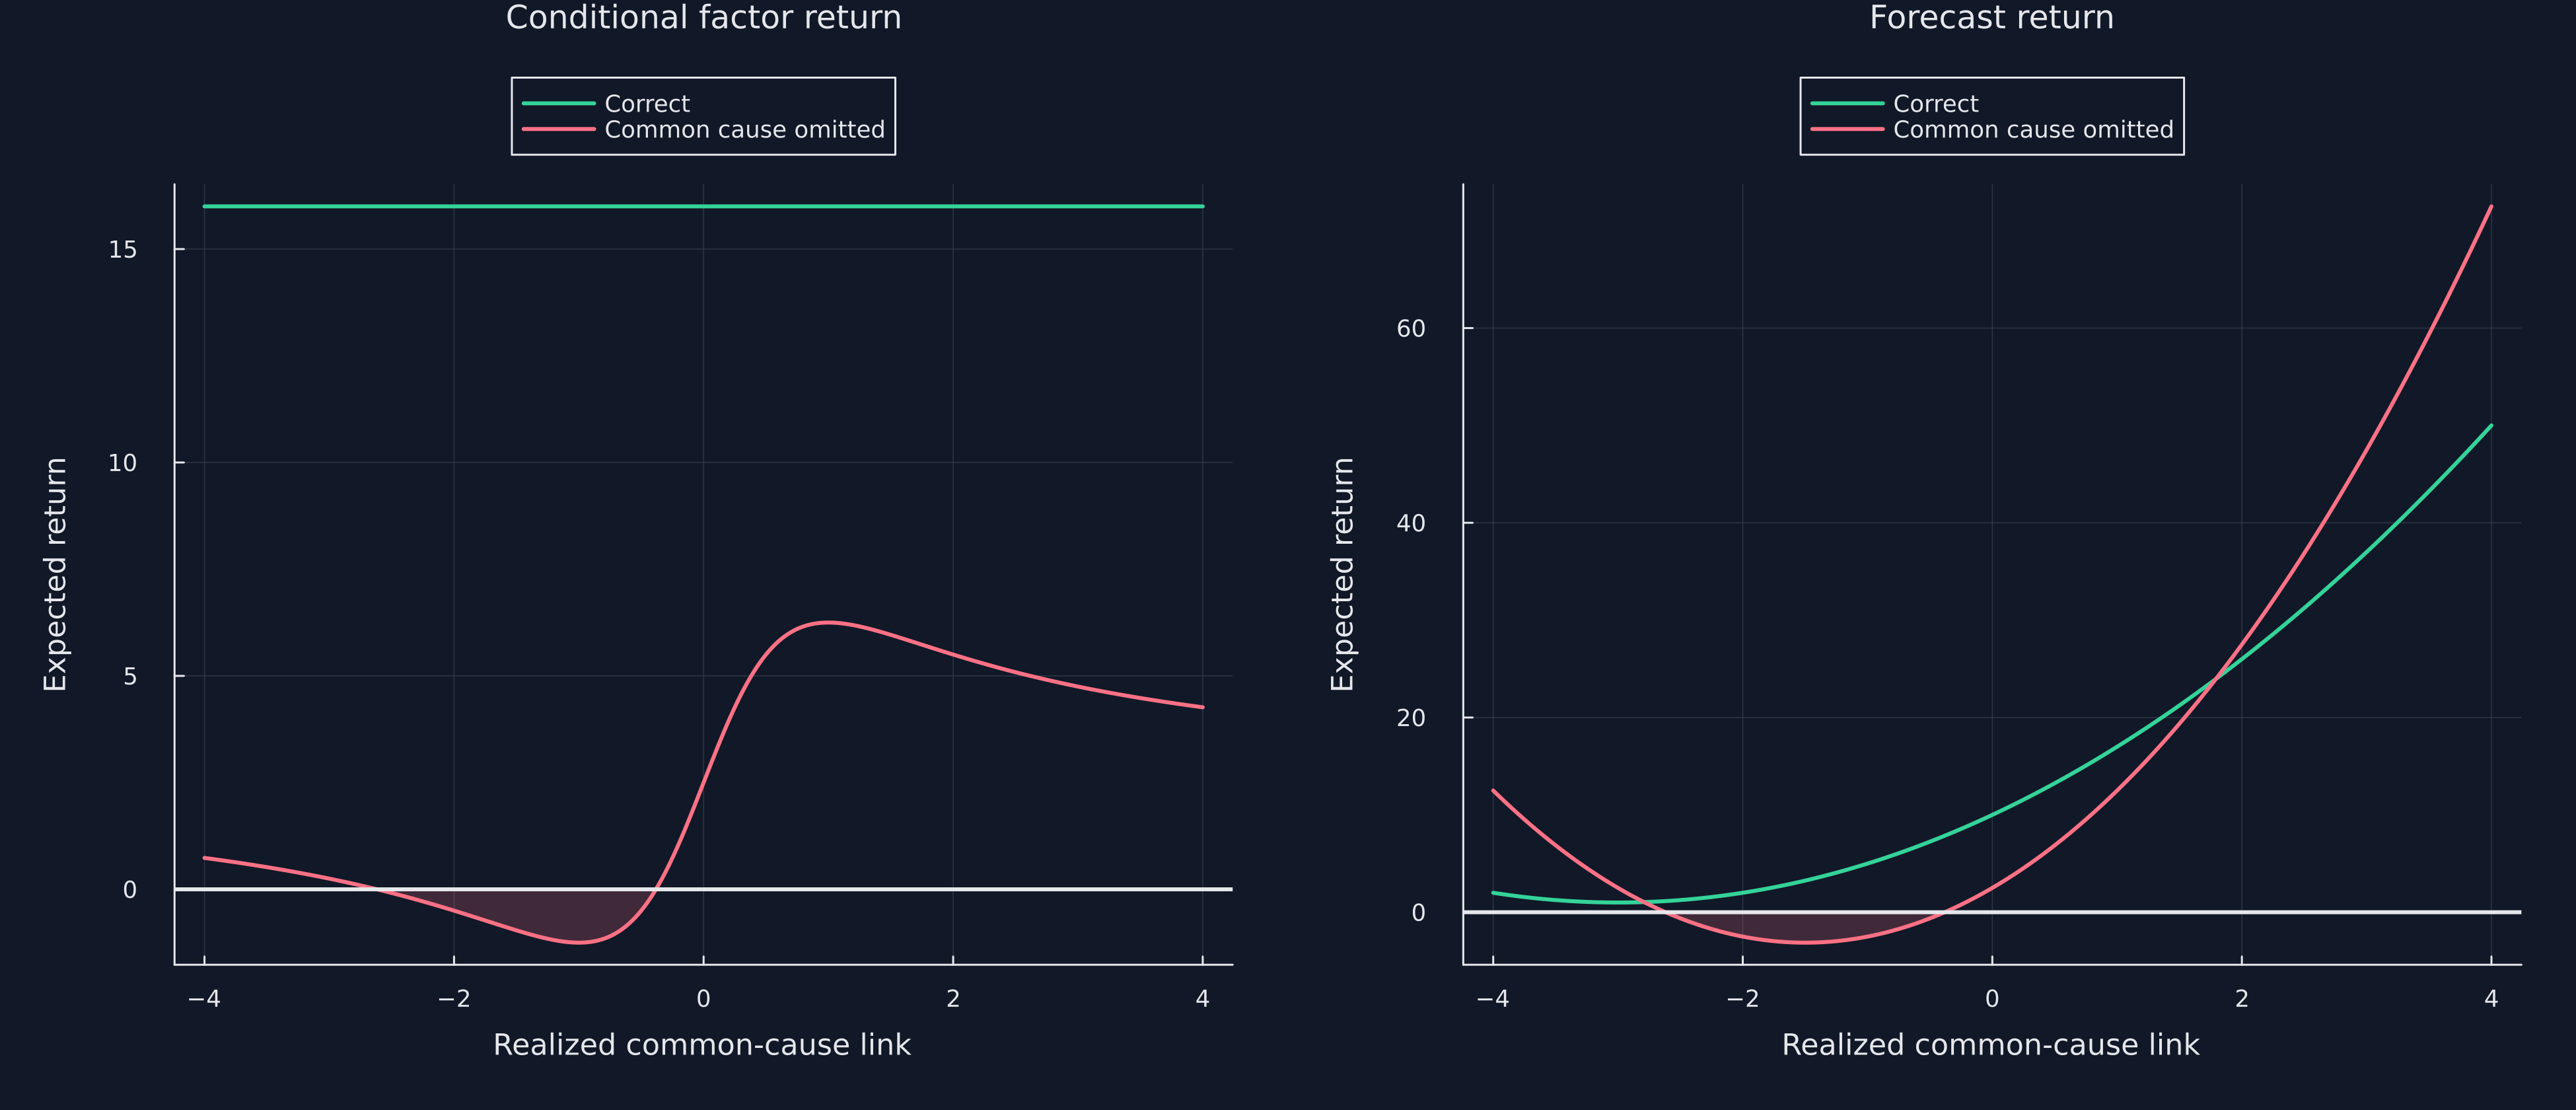

In [3]:
static_factor=confounder_factor_return(1.,1.,1.,3.,1.)
static_forecast=confounder_forecast_return(1.,3.,1.)
shifted_factor=confounder_factor_return(1.,1.,1.,3.,1.;delta_realized=-1.)
shifted_forecast=confounder_forecast_return(1.,3.,1.;delta_realized=-1.)
return_table=frame(["Setting","Target","Correct return","Misspecified return","Difference"],[(setting,target,result.correct,result.misspecified,result.correct-result.misspecified) for (setting,target,result) in [("Fixed link","Factor return",static_factor),("Fixed link","Forecast return",static_forecast),("Link changes from 1 to -1","Factor return",shifted_factor),("Link changes from 1 to -1","Forecast return",shifted_forecast)]])
table(return_table,"confounder_return_examples")
gap_rows=Tuple[]
for (beta,gamma,delta) in [(1.,3.,1.),(-.5,.75,2.),(2.,-1.,-.25)]
    result=confounder_forecast_return(beta,gamma,delta)
    push!(gap_rows,(beta,gamma,delta,result.correct,result.misspecified,result.correct-result.misspecified,gamma^2/(1+delta^2)))
end
gap_table=frame(["Direct effect","Outcome link","Exposure link","Correct return","Misspecified return","Observed gap","Exact gap"],gap_rows)
table(gap_table,"confounder_static_gap")
realized_links=collect(range(-4.,4.;length=401))
factor_results=[confounder_factor_return(1.,1.,1.,3.,1.;delta_realized=value) for value in realized_links]
forecast_results=[confounder_forecast_return(1.,3.,1.;delta_realized=value) for value in realized_links]
panels=Plots.Plot[]
for (results,title) in [(factor_results,"Conditional factor return"),(forecast_results,"Forecast return")]
    correct=getproperty.(results,:correct)
    misspecified=getproperty.(results,:misspecified)
    panel=plot(realized_links,correct;color=chapter_palette.green,linewidth=2,label="Correct",xlabel="Realized common-cause link",ylabel="Expected return",title,legend=:outertop)
    plot!(panel,realized_links,misspecified;color=chapter_palette.rose,linewidth=2,label="Common cause omitted")
    plot!(panel,realized_links,min.(misspecified,0.);color=chapter_palette.rose,fillrange=0,fillalpha=.2,linewidth=0,label="")
    hline!(panel,[0.];color=chapter_palette.text,label="")
    push!(panels,panel)
end
save_figure(plot(panels...;layout=(1,2),size=(1300,560)),paths,"confounder_return_shift")
save_data(DataFrame("Realized link"=>realized_links,"Correct factor"=>getproperty.(factor_results,:correct),"Misspecified factor"=>getproperty.(factor_results,:misspecified),"Correct forecast"=>getproperty.(forecast_results,:correct),"Misspecified forecast"=>getproperty.(forecast_results,:misspecified)),paths,"confounder_return_paths");


## Checking zero and sign boundaries

When $\beta\ne0$, the links where the omitted coefficient is zero solve:

$$
\beta\delta^2+\gamma\delta+\beta=0,
\qquad
\delta_{\pm}=\frac{-\gamma\pm\sqrt{\gamma^2-4\beta^2}}{2\beta}.
$$

Here, $\delta_-$ and $\delta_+$ are the two zero boundaries, $\beta$ is the direct exposure effect, $\gamma$ is the common-cause outcome link, and real boundaries exist when $\gamma^2\geq4\beta^2$.

Row,Location,Estimated link,Omitted coefficient,Shifted misspecified forecast return,Return sign
,String,Float64,Float64,Float64,String
1,Lower root,-2.61803,1.54653e-17,7.73263e-17,Zero
2,Upper root,-0.381966,1.06001e-16,5.30003e-16,Zero
3,Between roots,-1.0,-0.5,-2.5,Negative
4,Outside roots,1.0,2.5,12.5,Positive


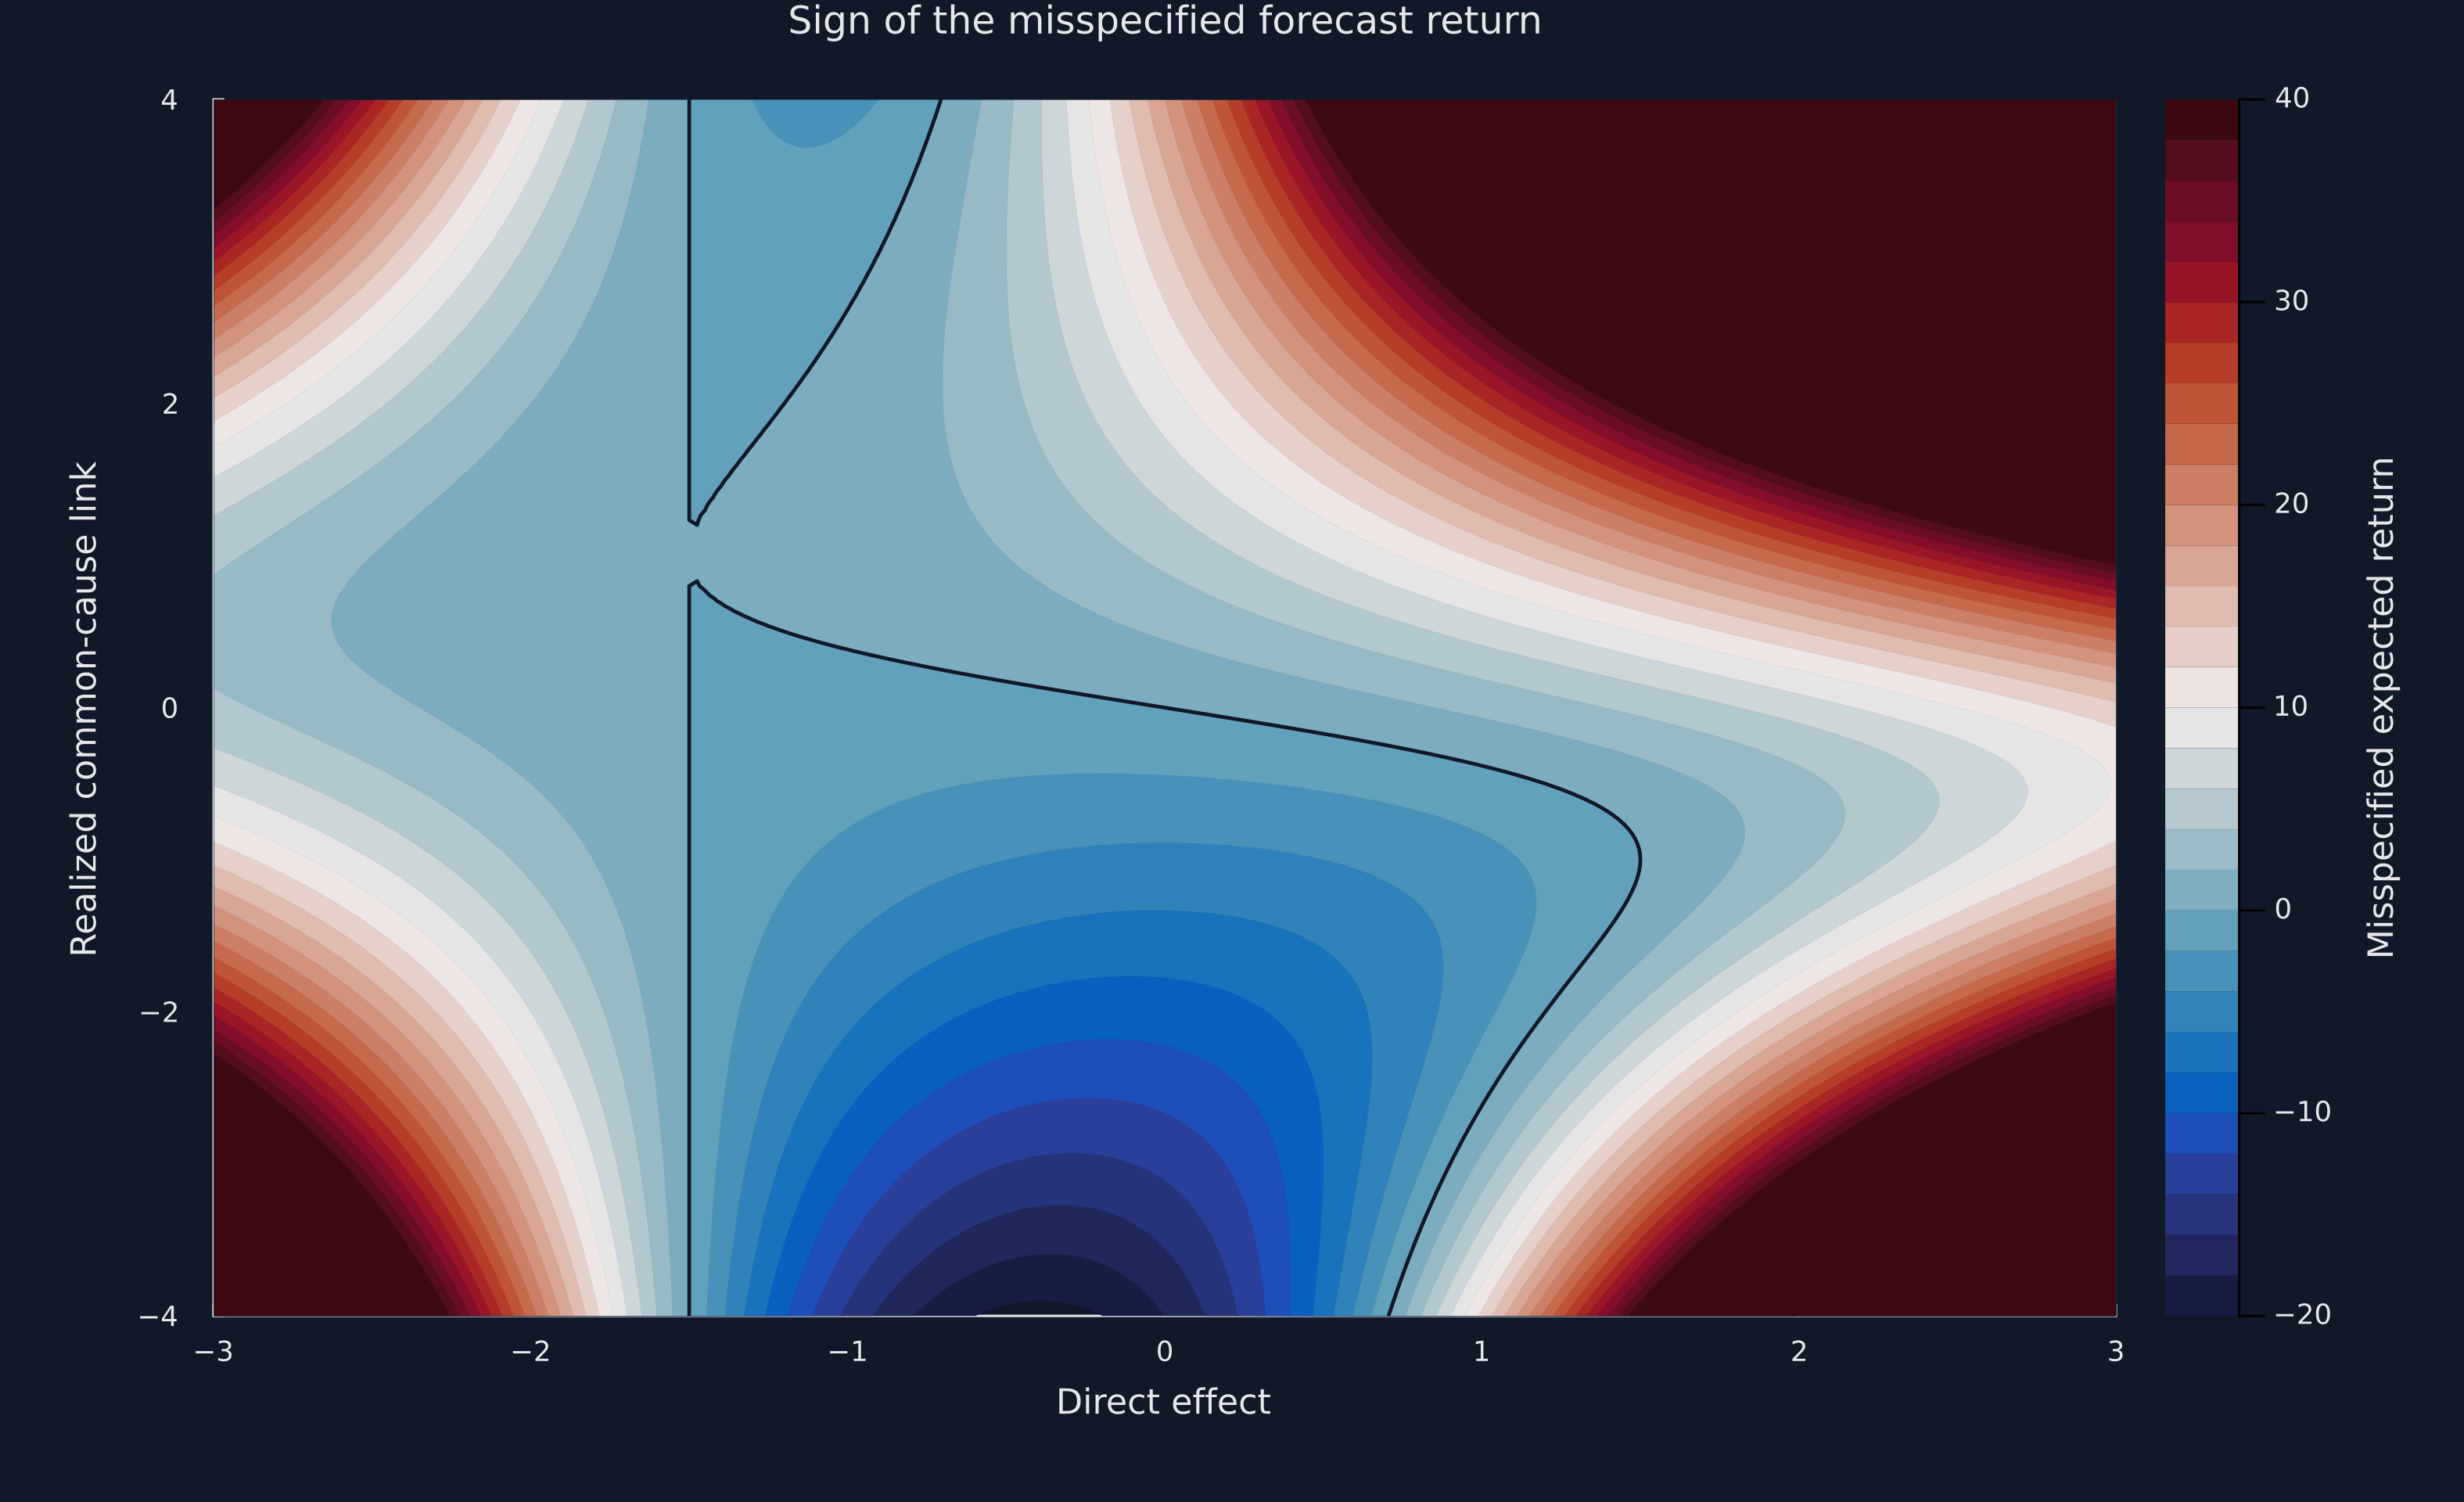

In [4]:
root_low=(-3-sqrt(5.))/2
root_high=(-3+sqrt(5.))/2
boundary_rows=Tuple[]
for (name,link) in [("Lower root",root_low),("Upper root",root_high),("Between roots",-1.),("Outside roots",1.)]
    coefficient=confounder_undercontrolled_coefficient(1.,3.,link)
    forecast=confounder_forecast_return(1.,3.,link;delta_realized=1.)
    sign=forecast.misspecified<0 ? "Negative" : abs(forecast.misspecified)<2e-14 ? "Zero" : "Positive"
    push!(boundary_rows,(name,link,coefficient,forecast.misspecified,sign))
end
boundary_table=frame(["Location","Estimated link","Omitted coefficient","Shifted misspecified forecast return","Return sign"],boundary_rows)
table(boundary_table,"confounder_zero_boundaries")
beta_grid=collect(range(-3.,3.;length=241))
realized_grid=collect(range(-4.,4.;length=241))
sign_values=[confounder_forecast_return(beta,3.,1.;delta_realized=link).misspecified for link in realized_grid,beta in beta_grid]
figure=contourf(beta_grid,realized_grid,sign_values;levels=collect(range(-20.,40.;length=31)),clims=(-20,40),color=:balance,linewidth=0,colorbar_title="Misspecified expected return",xlabel="Direct effect",ylabel="Realized common-cause link",title="Sign of the misspecified forecast return",size=(1050,640))
contour!(figure,beta_grid,realized_grid,sign_values;levels=[0.],color=chapter_palette.background,linewidth=1.6,colorbar_entry=false)
save_figure(figure,paths,"confounder_sign_regions")
save_data(frame(["Realized link","Direct effect","Misspecified forecast"],[(link,beta,sign_values[i,j]) for (i,link) in enumerate(realized_grid) for (j,beta) in enumerate(beta_grid)]),paths,"confounder_sign_surface");


## Checking numerical stability within valid inputs

In [5]:
input_checks=frame(["Check","Expected result","Observed result","Passed"],[
    contract_result("Boolean coefficient",()->confounder_undercontrolled_coefficient(true,1.,1.),ArgumentError),
    contract_result("Complex coefficient",()->confounder_undercontrolled_coefficient(1+2im,1.,1.),ArgumentError),
    contract_result("Nonfinite coefficient",()->confounder_forecast_return(Inf,1.,1.),ArgumentError),
    contract_result("Zero common-cause variance",()->generalized_confounder_undercontrolled_coefficient(1.,2.,3.;confounder_variance=0.,exposure_noise_variance=1.),ArgumentError),
    contract_result("Negative exposure-noise variance",()->generalized_confounder_undercontrolled_coefficient(1.,2.,3.;confounder_variance=1.,exposure_noise_variance=-1.),ArgumentError),
    contract_result("Required variance arguments omitted",()->generalized_confounder_undercontrolled_coefficient(1.,2.,3.),UndefKeywordError),
    contract_result("Variance arguments supplied by position",()->generalized_confounder_undercontrolled_coefficient(1.,2.,3.,1.,1.),MethodError)])
table(input_checks,"confounder_input_checks")
extreme_coefficient=confounder_undercontrolled_coefficient(0.,1e308,1e308)
extreme_factor=confounder_factor_return(1e200,0.,1e-200,0.,1.)
sign_boundary=confounder_undercontrolled_coefficient(1.,1e10,-1e-10)
numerical_table=frame(["Check","Value","Expected value","Passed"],[("Large links retain a finite coefficient",extreme_coefficient,1.,isapprox(extreme_coefficient,1.;rtol=1e-15)),("Scaled factor return stays representable",extreme_factor.correct,1.,isapprox(extreme_factor.correct,1.;rtol=1e-15)),("Scaled misspecified return stays representable",extreme_factor.misspecified,1.,isapprox(extreme_factor.misspecified,1.;rtol=1e-15)),("Negative sign survives near cancellation",sign_boundary,-3.642219731549774e-17,sign_boundary<0)])
table(numerical_table,"confounder_numerical_stability")
section_summary = frame(["Question","Answer"],[["What creates the coefficient error?","Omitting the common cause"],["When does the unit-variance bias vanish?","When either common-cause link is zero"],["Is the fixed-link forecast gap negative?","No"],["Can a link change make the misspecified return negative?","Yes"],["Does the calculation prove a market graph?","No"]])
table(section_summary,"confounder_section_summary")


Row,Check,Expected result,Observed result,Passed
,String,String,String,String
1,Boolean coefficient,Rejected,Rejected,Yes
2,Complex coefficient,Rejected,Rejected,Yes
3,Nonfinite coefficient,Rejected,Rejected,Yes
4,Zero common-cause variance,Rejected,Rejected,Yes
5,Negative exposure-noise variance,Rejected,Rejected,Yes
6,Required variance arguments omitted,Rejected,Rejected,Yes
7,Variance arguments supplied by position,Rejected,Rejected,Yes


Row,Check,Value,Expected value,Passed
,String,Float64,Float64,String
1,Large links retain a finite coefficient,1.0,1.0,Yes
2,Scaled factor return stays representable,1.0,1.0,Yes
3,Scaled misspecified return stays representable,1.0,1.0,Yes
4,Negative sign survives near cancellation,-3.64222e-17,-3.64222e-17,Yes


Row,Question,Answer
,String,String
1,What creates the coefficient error?,Omitting the common cause
2,When does the unit-variance bias vanish?,When either common-cause link is zero
3,Is the fixed-link forecast gap negative?,No
4,Can a link change make the misspecified return negative?,Yes
5,Does the calculation prove a market graph?,No


## Tests

In [6]:
@assert confounder_undercontrolled_coefficient(1.,3.,1.)==2.5
@assert generalized_confounder_undercontrolled_coefficient(2.,3.,4.;confounder_variance=5.,exposure_noise_variance=6.)==116/43
@assert static_factor==StrategyPerformance(16.,6.25)
@assert static_forecast==StrategyPerformance(17.,12.5)
@assert shifted_factor==StrategyPerformance(16.,-1.25)
@assert shifted_forecast==StrategyPerformance(5.,-2.5)
@assert all(isapprox.(gap_table[!,"Observed gap"],gap_table[!,"Exact gap"]))
@assert abs(boundary_table[boundary_table.Location.=="Upper root","Omitted coefficient"][1])<2e-15
@assert all(input_checks.Passed)
@assert all(numerical_table.Passed)
assert_artifacts(["confounder_graph_and_bias","confounder_variance_ratio","confounder_return_shift","confounder_sign_regions"],["confounder_standardized_coefficients","confounder_generated_check","confounder_general_variance","confounder_return_examples","confounder_static_gap","confounder_zero_boundaries","confounder_input_checks","confounder_numerical_stability","confounder_section_summary"])
